In [4]:
from dataclasses import dataclass, field
from typing import Optional, Sequence

import numpy as np
import pandas as pd

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit.library import XGate
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
import numpy as np

from src.linear_tag import (
    int_to_bits,
    bits_to_int,
    gf2_rank,
    tag_value,
    Transcript,
    KeyedLinearTagModel
)


# Keyed Linear-Tag Construction

## 1. Experimental setup

This notebook studies the keyed linear-tag construction of
Section IV of the reference paper.

A model consists of `nu` independently keyed circuit blocks.
Each block operates on the same computational-basis input
and produces one measurement transcript.

The paper-exact construction uses:

$$
m=n,\qquad 1\le s\le n,
$$

with XOR permutations

$$
\pi_t(x)=x\oplus t
$$

and secret matrices

$$
B_j\in\mathbb F_2^{s\times n},
\qquad j=1,\ldots,\nu.
$$

All model parameters, key matrices, and permutation choices
are fixed at initialization.

We first inspect the model and its logical resources, then
study its quantum circuits and classical transcript sampler.

Suppose

![Block diagram](./img/blocchi.png)


In [11]:
from IPython.display import display
# ============================================================
# EXPERIMENT PARAMETERS
# ============================================================

N = 3
M = N
S = 2
NU = 2

SEED = 42
X = 0b101 #explicit bit format

# None: generate independent pseudorandom binary matrices.
KEY_MATRICES = None

# To use explicit keys instead, uncomment:
#
# KEY_MATRICES = [
#     np.array([
#         [1, 0, 1],
#         [0, 1, 0],
#     ], dtype=np.uint8),
#
#     np.array([
#         [0, 0, 1],
#         [1, 1, 0],
#     ], dtype=np.uint8),
# ]

# None: use the exact XOR permutation family of the paper.
MASKS = None

# ============================================================
# INITIALIZATION
# ============================================================

model = KeyedLinearTagModel(
    n=N,
    m=M,
    s=S,
    nu=NU,
    masks=MASKS,
    key_matrices=KEY_MATRICES,
    seed=SEED,
)

# Full information is printed immediately after initialization.
model.describe(show_keys=True)

print(f"\nInput x = {X:0{N}b}")

# Inspect the logical resource counts from Table I.
display(model.resource_table())

KEYED LINEAR-TAG MODEL
Paper-exact construction : True
System qubits (n)        : 3
Index qubits (m)         : 3
Tag qubits (s)           : 2
Keyed blocks (nu)        : 2
Permutation labels (K)  : 8
Qubits per block         : 8
Seed                     : 42
Key source               : Pseudorandom
Permutation family       : pi_t(x) = x XOR t

Secret key B_1:
[[1 0 1]
 [0 1 1]]
rank(B_1) = 2

Secret key B_2:
[[1 1 1]
 [1 0 0]]
rank(B_2) = 2

DECODING INFORMATION
rank(A)                  : 3
Full column rank         : True
Random-key failure bound : 0.4375
Random-key inversion bound: 0.7916666666666666

TOTAL LOGICAL RESOURCES
executions               : 2
qubits                   : 8
hadamards                : 12
cnot                     : 14
expected_cnot            : 12.0
logical_two_qubit_depth  : 7
measured_bits            : 16
secret_key_bits          : 12
classical_decoding       : O(nu * s * n^2)

Input x = 101


,Block 1,Block 2,Total
Resource,,,
Executions,1.0,1.0,2
Qubits,8.0,8.0,8
Hadamard gates,6.0,6.0,12
CNOT gates,7.0,7.0,14
Expected CNOT gates,6.0,6.0,12.0
Logical two-qubit depth,3.0,4.0,7
Measured bits,8.0,8.0,16
Secret-key bits,6.0,6.0,12
Classical decoding,NaN,NaN,O(nu * s * n^2)


In [12]:
print("Total CNOTs:", model.resources["total"]["cnot"])
print("Total executions:", model.resources["total"]["executions"])
print("Rank(A):", model.resources["rank_A"])
print("Full column rank:", model.resources["full_column_rank"])

Total CNOTs: 14
Total executions: 2
Rank(A): 3
Full column rank: True


XOR permutation family:


,Label t,Mask,Output
0,000,000,101
1,001,001,100
2,010,010,111
3,011,011,110
4,100,100,001
5,101,101,000
6,110,110,011
7,111,111,010



Block 1/2
Key matrix B_1:
[[1 0 1]
 [0 1 1]]


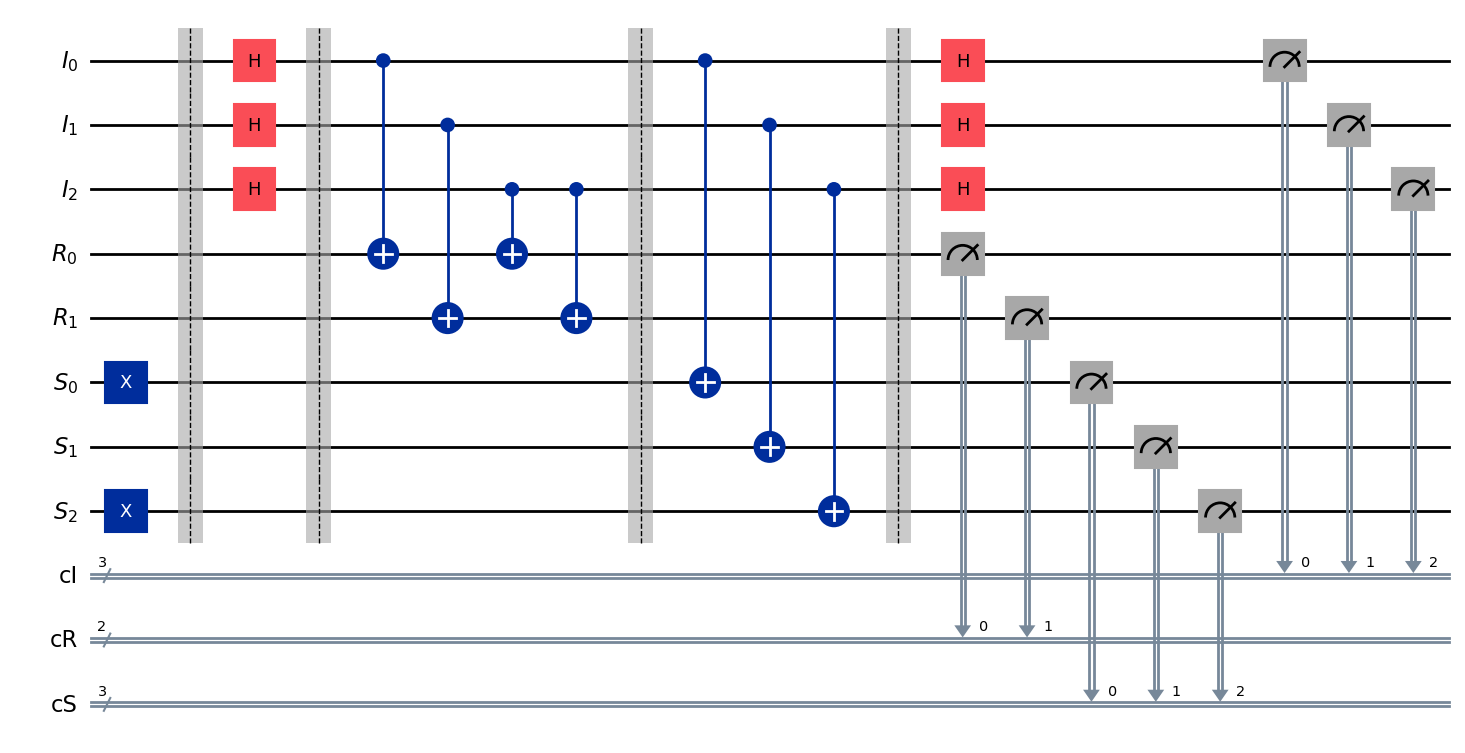


Block 2/2
Key matrix B_2:
[[1 1 1]
 [1 0 0]]


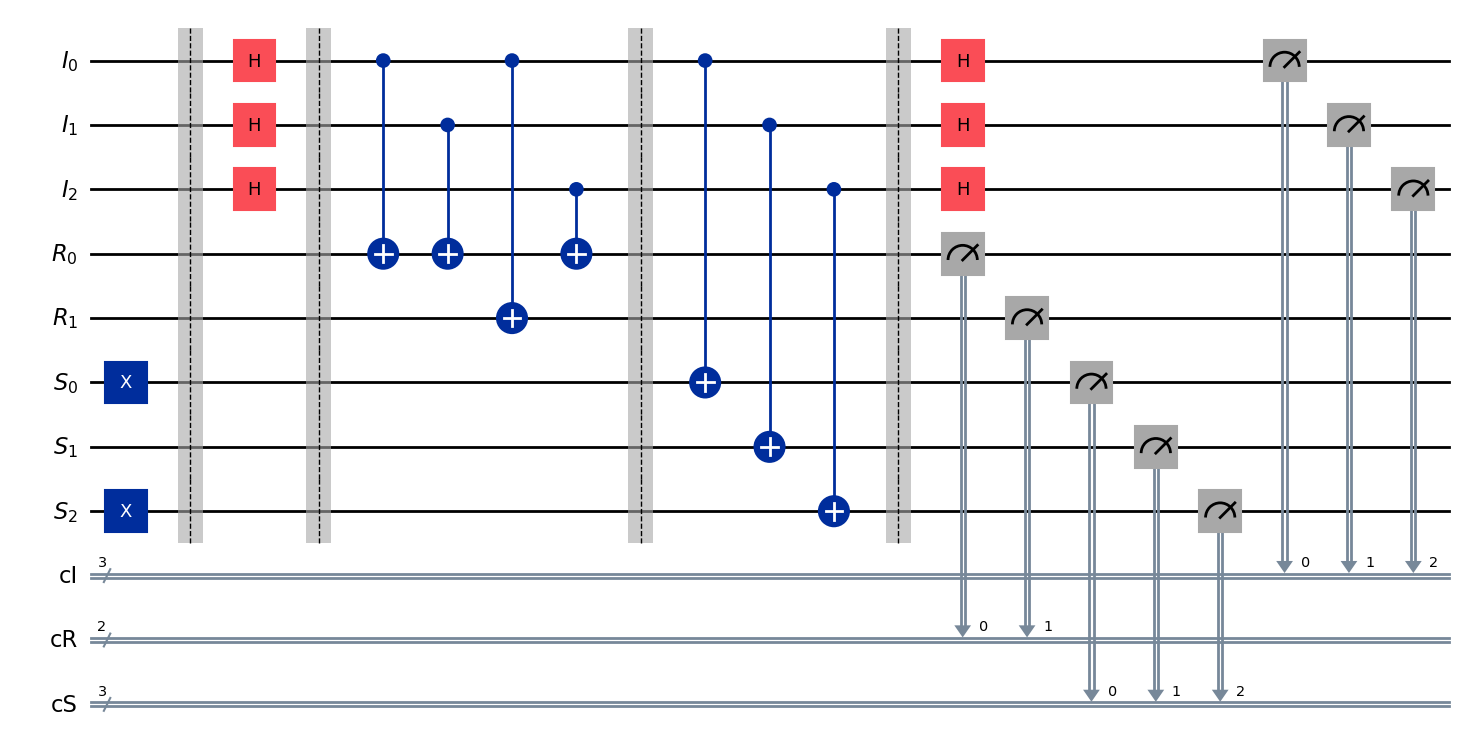

In [13]:
print("XOR permutation family:")
display(model.permutation_table(input_x=X))

for j in range(model.nu):
    print(f"\nBlock {j + 1}/{model.nu}")
    print(f"Key matrix B_{j + 1}:")
    print(model.get_key(j))

    qc = model.circuit(
        x=X,
        block=j,
        measure=True,
        barriers=True,
    )

    display(qc.draw(output="mpl", fold=-1))